# MADT 7202 Mid-Term: which interchange should the Airport Rail Link plan its first bus bridge for?

**Decision (hypothetical role):** the Airport Rail Link (ARL) operations manager at Asia Era One chooses where to stage the first standby bus bridge for an interchange closure.
**Network:** stations are nodes (193); an edge is two adjacent stops on one line (186) or a transfer walkway between interchange platforms (17).
**Metric:** remove one interchange and count the ARL riders who can no longer reach any non-ARL station by rail (*stranded riders*), weighted by real ARL ridership.

**Files this notebook writes:** `data/` (the embedded inputs, if missing), `results_main.csv`, `results_all_pairs.csv`, `results_robustness.csv`, `page_figure.png` (the figure printed on the A4 page).
Run top to bottom. The last section should print **All reported results reproduced.**

## 0. Legal basis and access discipline
- **Ridership:** Department of Rail Transport (กรมการขนส่งทางราง), dataset `drt2566_02` on the MOT open-data catalog (https://datagov.mot.go.th/dataset/drt2566_02), licence **Open Data Common**. The portal's `robots.txt` disallows automated access, so the CSV was **downloaded by hand in a browser** and is embedded below. No scraping.
- **Base network:** `Gusb3ll/thailand-public-train-data` on GitHub, licence **CC0 1.0** (125 stations, 2023).
- **Lines opened 2021–2025** (Yellow, Pink + Muang Thong Thani branch, Dark Red, Light Red): station order and interchanges transcribed from the Wikipedia station tables (**CC BY-SA 4.0**). The map positions of these added stations are interpolated and used **for drawing only**.
- **No personal data:** the ridership file contains station-day counts only.

## 1. Configuration (edit here)

In [1]:
import os, io, json, gzip, base64, hashlib, collections
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)

WEIGHT_START, WEIGHT_END = '2025-04-01', '2026-03-31'   # ridership window used for the weights in the report
TRANSFER_COST = 1                                        # stops charged for a transfer walk (robustness re-runs 1 and 3)
DATA_DIR = 'data'
os.makedirs(DATA_DIR, exist_ok=True)

## 1b. Embedded inputs
The three input files are stored inside the notebook (gzip + base64) so it runs in Colab with no other files. Each is written to `data/` if missing and checked against its SHA-256.

In [2]:
EMBEDDED = {
    'drt2566_02.csv': ('...'),
    'stations_cc0.csv': ('H4sIAOgH0WoC/7VcXW9UV5Z9z6+4Ur9eRef749EGJ0EGx0PRE/F4g6txje0qVK6C4S1kIuGQiTTTgQHCiGmDkAkM6g4BTfnf+KfM2vucc12O3Z3YV6BgXHbXvavO2XvttfbZt+vtSTMZjIYX1uphs9XnL0vD6/X1/uhiM+F/8GpzMOyv0K/LN0v5h+dGm6PxZ/1/5Re9/vjm4Br//iNZL8j6YPbqYDY7mO0dzJ7zfz8czP5yMNs/mO0ezN7VvenNZqv5cn26Nail/tjFYLQwTqiogtO1FOJjbxX9Mdo571x9sH/nYPaGLrX/7wezp3PfP6gO9r/ie7yo8BeXP5jdPZjdwS/rhcH4xmg8qS43g83q4mC4Uf9BaK0+CfXChcurn1++cvHCyvJHql5QNb/17cHsPr2Vrva3g9mPB7OfcbEa61Etj5svG3x2wPXKByW90d4EGVWCazyQCmF9EFZ9ULi6XtA1gdv/lhE/Ppg9ZKCAe6/88G692AyrK+vNjercesGtVZBGyiik8i7hdlFqGVQULlitPyhuUy8Y4H7NWPf4m13Geqf+bNpUl5qNBDIIbTw2PUiZQsEZK73WPmgtgv2gGG29gBvQFd4yum8OZr/w/V7Tkl5utjbWm631pp8XFFGrlTdKW4d/ElghpEUY4OdO+w8K1tULSAyC+TMH7R0O2lf88nGN9dxotpshA7VShqCwhM5I6xiodcJbHfERgg7hgwL19YJvV/XewexJ+R5f/4JVnVxDnI6b8ehGAmtljNpE76SKKQSsURJsEL2yIcoPChavsBp00e8J4z5C4GG9ut7cbiidBgkhcVIUKuio82pqE4wEL/go/Yelq1ivyLnVpKs95IR6n5dyst6/lXGCQINQSoaoTAGKAHDWBR+iUYmocZ1nhbG/5q+7fMF39NF70w3w9M3BhBD16z9EdV6YpXrxSu8jKeoV9TvWylgH6nFCI3sTBu2sEYBERNQRg6xXiA7fMBHOyrVS4XlPF6VVv8dJkW6wm+LusBr98+DaZDS+XV0aDadb/eGEYTuEXgjgS4slNBm2l9JL7DNyJnSEreoVky7xOJMNbeSTxN91r0E5rlabEWPxKlihI4hGaCFLQggTNcIONajrEup6xaYlfDu/bPXCOG1hoNsG54JxUZWExOZJkJwEt8SO9zf1ik+X+BsHUypq3/Cb6aJYjhsoYtXy+q0cVLQ3IlJAWekKIhCGRn0LQvquiGy9EupSot5w/OA9D+pLI5TTAUcI8soKo0KMCAmbA9vqoITi5PJdI8TVK5ExpJKO8KAIecY832qVp8wrqebv1Z811dWmv1GRYFldH6fwQXw4UTbP5vBxwKyNDlJAfHUE6kFIItHAa4K2/zVf6RG/9XGlDFHC+mhYXR1N1gdD+gHBUka56IR1WLRYapKDCgQskIPqGtUBsDJR/sxEeQRW5srbDInxIMa9idZ6gaIeM56IaDKeKMB3hEO0TcLwq7mkf8zvQ6Dv1r3+sKlWBhvro62ExtkYsWORAjyj8dAZPgbFdacbHAXqljqph9eFMd9xJXnGL19kxiS8CLifEP28lC/5t6/yS5DEcrPdn2w3KFt/HA5u9sfbg8lt/gTYXim8MEKgUIb8CbwE+XsBaWQ65qgC8Uui0CTXd5k8d0oZAp1+W18e3W42q09G4/72pDrfvwGQhd9BqE5iMcHpEfgSuoACbgUyGGW8Y2lU4HdpWaazHC9mYo90+fVqcdokFE6BSSFtrFc6r1EAoUqDog151hEEiJ2LQ7tED8tuPy8C4kf+4XssXYVskXKyXl0Y/qkZTlAQL/evD9oFg+SJxhlS59ATCWqUUGSSVRB/2C5YUQQk5dger1OhNqoIL0tRamP1EX9FBM7qLzLVVb3xAB6C1E+TAHsRYNAADaLR5gzCKwh1lFIwddcdRo2Q4e/THm55lPYIA2DB6kqQngsoEzZbBhRX0KDFC2k6okLVOFqPX/NXXOA+yuigujpdSzCCh/hCUUASeJ9xGIUdJZ0Bo9ARB4qCEseK+v6/5aK6v1OK+qVU0lECIug2Ynusj8VLRWGJkVHupewICOVAkXP4mqPpLmN6VlIgEd6hJuTfvuDSf59v8qJwIV7eqxepc/HlaLNaWJtu3m7W+v9SfTbavjGYNJv0WaKEWlMxhCiMLZuM4iIM1DAox3WlPtQSlYX3u/L1EeP/mVst/8miN1mQu6U98LQovDv89WWmRxLqFZwH8eS1fnVput2fbqVPEUBMUDkWRKRyiICVHJlI2pqOFVGTe8gtB1I1FVdCeMM3H9esYpZH42oVfxdGY8YDlkQh0U5TwsiMx5gYoxUidIwPjXKiKPm+4SD4htTe8voUmnPEdBI19aJIcistsyGAWHHwoyhwtquIAhst0SdIQvM+B9xuTVqzupgUgTfgXRQscJdoHQm3zSS2iPoQHRHoeinrk6fFmEKf7GTlu7o+GPWHrfoFiRJ9WIl/2soFtkW8gHIDQqYjGlMvUfVrddLbegWeKN1aOFCCArF757Putho8YUAdVnUsmtrWS4bdEFHFS2pPLWyPcm/KK8ReDJLupUsbRZOWFsKpjhVFu3rJ1nOa/g2/8ynn8E+ktVDoRrCFKCq5oSes9B4p4cHnpkhWr4QE8WjI6I6AfL1EdeBhIZJU5xASb+orBAKxmRqiiIYgYDGoimUcqC0wHrDP4MGuWxLqJZ9C8w3TV2p5PauXNpabrWwJZeSOoSTpJEyRUiLE1OtQXfkh1kuhPlQlFBxfc2TerVl/LKOYlX2RVjkIXEdewhSppAx1WQlKx9wwol6KKUJ3SuMj9T7u1Z8Pq5VpylBh4V3A0lA83pWCiq+QaqhESJmOKCQYS8wr3J3czWWFe2499XNh8aKIGh/fkmPOMCz2ySF8Q+dGiiHipL19wm/6gf9L7/svaomtTofD5tYACozRIBygd6SShog8o4FZd8m0i46yB6SwRC6PdmXGPL7bXqb+4xqSF29OQLAYSsMIQf4XseMFpBdSBpHcEQbYU+r5vWEG5Y1ZYRIl/RmpnOCzK1XkHzwndslDhXWkMgMSJSmbmxY/ctK843i9Wy/2m/EgZYpzErGoJDZD2twEQJB674XWEunTFQcotTiTX1rtB+m5Nc65ihpulKFmPXy1z5wOztABxS0gVrpGBDiUPdgT0hVYAFqPndzmW51SnjCHwhFrR7bYCLgV3forC3dI5za6a7qCQ9lfHR4RFUJ9Xvw/iceaj4uqpXFzK50dkOQzpF1BGeXUyNIRklYSf3xX5WNArOSjWmGe2+PchMzU9raob/z8/6j6zEnXleYmvl24BhW+xY0H5LNFhivUaVGUSTQo2lpDfuuO2tuCfNlgPSla+jEv6C/1arMBMFsJAu6uLSyeQlnMvUHQDlSqwRoa11GrWXAvu6vWGqd+6fOi2h7m5gxM8bC5Tum2Nua8t0htiZ2MyC8sT0uAMFio1yrGjmXSgo7ZZn1VlOTz0j96y3USur6XkEAt0EFkwHKIUhdQsRITwyV3BEJy9gh7vOD3JRd8cZqaBBbqSRrK/XBYmjykHLFw1746lNASG5yveHNesxP+K1xFfz2tAIqA4TNNrETZCu/pQJa2oquERoE/t7SSrpGM7m69PWiymbCkWal3Q9RXjrBExM8D5BOcEL2X/qZrufoLefS4gnYVgfe/c73p14ng2cWk/sw7qHYaMkCG9ibN2mCa7+6cF/BtKIAye33oRIhZyHhivF998PfZDvUGm6ig6YMK4c8juxmcr3vzJ2JUdn9JyZC7vGvg+6QSdaR2MyysonKXP3e0ypN6NPFYx+23bh3qnqpLV/TF3FrcT3Vms6nOt8fFCjcGyyPylSjORRtJigwbYo6Vmt+6eax7OjH6TlHojw/TH+LnHIv0ldFwe5B1Om4G9vEgROHLuhtYW4fI096fDoATdS8V+dl3fN8H3Hdgl0BxyhchFmoGQ/Kx08F2giFhXCJKGtSpzRUFghnhELAOMcRTwpB1z7YjJ6lHnU7E77PoAIDpuNnO8wWSer5Qo1qBC3N5IEqk2BMGKuSUN1d1zx0/vHpQqsOrfNyQu11Xmo3tdN4AINQYB9V5h1qRgEhqTQqYfPzmlFmALO75ttc742h4xFh+LOvyvl4eTxEQ5N2qxWlOCSrjWHTq88CiJBxCeTp7h0gWp40JU/dCauOmUr53WMpz9+976v59gci8NcCKXG0KDA3xC/eqRZSJE5CPEjUbGLQ4ZWKi6PZiEhVPc0+WQjMduKQOHx1goCSNqpXBVm5qcNEW1F5Clqb8MMEGTw0HiMNjR3q/BcKBmKhMPzh6Yofv9+sr4AZqXW9O060h/KiXIwXoNzkCEAJKNGRx1F6ZU96aOFGmfcDm//lI4++L6WQCe9bkD62pD2xp/srkc0zjSPkKPmk61tj/rTuDEtkCtd7jNaFIgpcdyBepjaMECBFmGKkXsq40ND6FEgRWCPK0nzjWn8ozxj/8KdSQoTPtHP90PhVBivoEFLkdUn862lzLOBYXkMyOcXhRf5r7aDtFkX3fCjSS12NqpK00G0CRAKAawg0bxIDNrXhL7VWvlaKmpzs1BFl/qlMr80UpDOkCj6E+Nqkm9PJgkBY0nGGR5wbkm+/toYIUHYWe4daqXrwoJDeN0mlc6ZjUUOt8UpM+M9nOGLSh7lXOdppvoE1A2J3AfVlm88LezaS6uDntZwz+fBCf6PrS5SsfwcUBA4XgTjn9xQb8tYIjptUH59BgGYsBfH7YLaeRaDndPU1FgYHJMuhOKAyhIPmHbfifg9m3eZbhE8jPc+1wjJVwvwIf3dCRS8q9iHIEVwo1FlwnBJYQmPlUTPrx8aFOQHHknFxenw5JKKTZF1g7BJ8JsHmmbA7NeiAthDmRi0+ByhGqI0ejz9IBJMPj2TWGdHXAPbU0AeMt1gX2GLwQbSFmaDhFBYNsaRdEnhDlpX4356IeUcL2BuSe1kfjhISmf6jXiPgoFSLS7BeSCPCE7QQkEBA/vzRPy0n8/bQoqBeZtiMVbBKxKuQGDnI4YqW0c6rrikQCEuaBvEkd6YTi84QgwGiTYYOF07rwlqd5M4usjqELhCAIQpyDwLW8rEKabCExi71AHATEQdFygo4DEBXWdApUCLDFi1S+6X+a9Bz3cPCGK82oWh2lbAEIReOVKNzOlH4DdTYpUQINLnYCQXzKhbzdie+oB5Ka8LwYvWk/4dBS0OlYQOWSZWINJhakiogIPnbCQZzKZf1OGYl9WhReIvh79XKzdYNnY7E//RykQbp0XBNCO8oJ1gvOxOMTPqdDRPwq8w7vlbOqB0xwO8UAcL2dTGEBN6rVZryRB7ccpCaoLdKhRRnc8iFSEdS6234R57J0OXks4OhMQBrPMhSqAEXG35dDJUltESyfEJ0yORDbsoT7OyNjR0fFYEWxKCEGEZ2x7dSRh0WBWjveFj4dFuJZbqqUkSyC85bPrd/x+3+i44Ni2W+sD7b7ybPFSAOI3tO4WOnRUguDrLPWquOWEetK3xrIh2Wz0hVRAUguD8ooNRZHozrCIiHjWyxKRMMnYKEbFiJeGdqxvz2+ytdlEvIuTcoPeA4ytxSgGkSk9jAUrC9DVhqrgpxDaZCdODgSB3Oz82UivjJOm3rFf26LZB4vSoPyuQf0pByUpfnkl2k6mBQQtW03m+FadW66OYEz36zO9YeTcT9pD6fJiVsIcu9zXUNJcZQRngZBOn0gonQl5o7xyqh/FdMp3uVmq4pJmiHqInJQ42so44mWjjWDVMHGTpU+Eq3nPmnhzyNGhRgUWfBlMSkmBKoyLtBZQF4WrJRAWuCPdaYTGiL3ktv/sMuYn9BwEZrVsXgvWKRxHjtmUX870XokWucz/F/F3J0yt1YCi1ZsdizsDluPR+XcneL5uSH0T9M+PBhJu43BpGp7lOdGw5sIRbzgkOyPk1eB9IVDpMQ3un14gtyrSGW/0+elglEGT4pby4rjWXFrV0b97FUVzTlQiwKaR7czxx5VywjtuvFzpFqhcq2YldmDJIXf1xenqO6DYcZBR2SBbFLQZTrVkBi0VCxst5oVqU6UVT10/e0gjIqGngyDgohlThd0x5PE0IHddoNqwdwkzS5H3072zj2Qw9VinLET1C+AV4P+LaqPNgboUNE7Sc9IZUCF+aelXpQDzKe5DFQXSW61kyAeG0LnGDBquYchqd0b4ZtsR02DqxGcOD+cmSYw7maRRUOYl1CSNrKBRDlUUKFYGCliaW1CnzI7WBO6oSES1+LoHvGkXtqgUR5Q8jzl4OhZnWJO6FDQInjl8ZGUU2Ig/ta/OhGhAncvPa5AT2+0Jt9QCfEWitP5bBBMJPpUZA86uhQsK0HJMweJ9NLjLdR6qS/QaDa1nm9k6obGJdVr8Z9rfbSkcZU0ht8JCnG3np87oCX5b2r3ZttWer0w8zAkLsKwytJytMgoKaXCuvhuMIhSuXFXelBzR8f/sC9ZrQ4K58NEUn/KORna3qSMwZEIlh3xEc/Sef588T+cs9+tkCBU/zea7f4WvUgjRXCXJlrslsnHFsZYMD6PA7qOiIhxNW1+ipufuCFzpINJxmWbO1fUvkyQFJ9cwr/IFhI2Twt+BEYr2w0TUbGeb4ZQnf+mtKuaJBdlmpWHiTJe5bY5iiTkIgqTFR1Ti2hYZxp+UTzlq9wAvQhP2WsnvkiKIT4CEV6iG4MvNBToYhTddDguXq+ucld1vqV7LMmyWjiSa4EPWZWkZyqLBTciIMs8n7We0BXY5azZ48m26fjGZkHkzqulBZERSUKkfnW20SKaO+ihc461hCkf9dAiBaWwO9SpyNkl6OEkhUoFL2zOiEkRJj1XGMpo8cnIUjnvbxwFR7bJ0NMYSPZMTRKV3mLBVBTRnxGbJmzmeGtvv+3rTdPtkeeKD4mV1LnBSOaO5LXUJ54K/q77G7r/ka7r8xzQ80vCWC4jsNvVgKhAfYjAokuDGspLBBNhRqQ7a/hYguNOgpPz4g1fsT1ESLXtPw4BrowGNP9TXcgPexgvgiQPXGYdQY7Sh4DSi1qnzwjTEUxfF++aXG5+QpMeN8kPmkAF01MTsNz5USLj6A+PQ0MQn/Hmnm4ejp8tt971MS1Z8j25fLwog2XkZVeYKTebUbU4Hqxd72ewFExUNfhhk6QA+DnGoPERzpx7gcDGei7l2lGEQ1tbyTTZvzIaTpK5xU/44SIbPXLLaulkPoMz1FChYxCw+Un0+btQwdWvHh1Sbf/PHV61DdTlcbOdHjEIuFOg4xh4CZNPPughT++RBAisk3zN78GhiL+5i/srU9uOrLTu9oRVq+eW69zg5uDanDkNTpDzNgRalRkCRSEv6fHlM6anInYv3d60XCn69+bOEh8VyD8cjrhegkHcpkfHRn+qVqdfbgLrZ/1mc7KenggMkDH04ICRrnTKpUGSCprIVfqMu6yI96Wej73k//dKxpSjLg6+K4NbNKmdnrKM1FyCj6NHPItRMdQIxv4HF8+638T23AVOC/aSN5v71JnP7vIARNVrSicvaPh3YwNNYAndDsU4C+o2hib8zwiFiP/ok4jftXPj+QAhL4YSDloFRC9cGUqmB3+Ex1/hvT/rYhDXU1PoN89RDNVXQ88TlueBASXQKAo/zXCm2/8/4HYOpedGAAA=',
        '0dff2ed1400f0103204dcd26d0de9efd39309e53605562ad3d0ba7602a8f70ad'),
    'transfer_links_cc0.json': ('H4sIAOgH0WoC/3WTsQqDMBCGd58iZHYwiUbtFqG4FBEcS7dS6FCE0q303XtaOuT+u8Hhwn3/lzv1XBjzpscYe7/ag7Eu2fJX357rYztJ3f/ktW715C2VnxLIgZPUmZGUJJIenTEnh5N3CgvWvTf3RmtEOID4WINYGTdIYjYwpYlsDd7FgzcqrORl61qUOzfobXNyVNbcgHVkS6YkkYzodDBsUBYVhWEDe0VbnAi3YJ56LnaKuBXEjokpTWQ79HbgDQoreQPzKr9RnwS2ytl5dsp31YN57+X3rna6uJgvyM4lwDoEAAA=',
        '44ec9a481d0bd1ff318146337120db671a80633f29cc835e69f1a6bfa213b79d')
}

for name, (b64, sha) in EMBEDDED.items():
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        with open(path, 'wb') as f:
            f.write(gzip.decompress(base64.b64decode(b64)))
    same = hashlib.sha256(open(path, 'rb').read()).hexdigest() == sha
    print(f'{name:28s}', 'OK (matches embedded copy)' if same else 'DIFFERENT from the embedded copy: results may differ from the report')

drt2566_02.csv               OK (matches embedded copy)
stations_cc0.csv             OK (matches embedded copy)
transfer_links_cc0.json      OK (matches embedded copy)


## 2. Ridership: Airport Rail Link entries and exits per station per day

In [3]:
d = pd.read_csv(os.path.join(DATA_DIR, 'drt2566_02.csv'))
d['Date'] = pd.to_datetime(d['Date'], format='%m/%d/%Y')
d['riders'] = (d['Passenger_Arrival'] + d['Passenger_Departure']) / 2      # mean of entries and exits
print('rows:', len(d), '| stations:', d['Station_Code'].nunique(), '| lines:', d['Line'].unique().tolist())
print('period:', d['Date'].min().date(), 'to', d['Date'].max().date())

ARL = [f'A{i}' for i in range(1, 9)]
def weights(a, b):
    s = d[(d['Date'] >= a) & (d['Date'] <= b)]
    return s.groupby('Station_Code')['riders'].mean().reindex(ARL)

W = weights(WEIGHT_START, WEIGHT_END)
print('mean ARL riders/day in the weight window:', round(W.sum()))
W.round(0).to_frame('riders_per_day')

rows: 12408 | stations: 8 | lines: ['แอร์พอร์ต เรล ลิงก์']
period: 2022-01-01 to 2026-03-31
mean ARL riders/day in the weight window: 67476


,riders_per_day
Station_Code,
A1,12751.0
A2,9776.0
A3,3419.0
A4,6298.0
A5,6269.0
A6,11410.0
A7,3921.0
A8,13633.0


## 3. The network
### 3a. Base network (CC0 dataset, 2023): 125 stations
The dataset lists stations and the 9 transfer links. Edges between consecutive stations are added in station-code order; the Blue Line is a loop (BL01 to BL32 back to BL01) with a tail BL01 to BL38.

In [4]:
st = pd.read_csv(os.path.join(DATA_DIR, 'stations_cc0.csv'), index_col=0).set_index('stationId')
G = nx.Graph()
for k, v in st.iterrows():
    G.add_node(k, name=v['nameEng'], line=v['lineNameEng'], lat=float(v['geoLat']), lng=float(v['geoLng']))

def chain(seq, kind='line'):
    for a, b in zip(seq, seq[1:]):
        G.add_edge(a, b, kind=kind)

pre = lambda p, n: [f'{p}{i}' for i in n]
chain(pre('A', range(1, 9)))                                                               # Airport Rail Link
chain([f'N{i}' for i in range(24, 0, -1) if f'N{i}' in st.index] + ['CEN'] + pre('E', range(1, 24)))  # BTS Sukhumvit
chain(['W1', 'CEN'] + pre('S', range(1, 13)))                                              # BTS Silom
chain(pre('G', range(1, 4)))                                                               # Gold
chain(pre('PP', [f'{i:02d}' for i in range(1, 17)]))                                       # Purple
chain(pre('BL', [f'{i:02d}' for i in range(1, 33)]) + ['BL01'])                            # Blue loop
chain(['BL01'] + pre('BL', [f'{i:02d}' for i in range(33, 39)]))                           # Blue tail
for l in json.load(open(os.path.join(DATA_DIR, 'transfer_links_cc0.json'))):
    G.add_edge(l['from'], l['to'], kind='transfer')
print('base network:', G.number_of_nodes(), 'nodes,', G.number_of_edges(), 'edges, connected =', nx.is_connected(G))

base network: 125 nodes, 130 edges, connected = True


### 3b. Lines opened 2021–2025 (from Wikipedia station tables)
Without these lines the network would be the 2023 one while the ridership weights are from 2025–26. The Yellow Line matters most: it links the ARL at Hua Mak to the Blue Line (Lat Phrao) and the BTS (Samrong).

In [5]:
def add_line(line, codes, names, anchors):
    idx = sorted(anchors)
    lat = np.interp(range(len(codes)), idx, [anchors[i][0] for i in idx])
    lng = np.interp(range(len(codes)), idx, [anchors[i][1] for i in idx])
    for c, nm, a, b in zip(codes, names, lat, lng):
        G.add_node(c, name=nm, line=line, lat=float(a), lng=float(b))
    for a, b in zip(codes, codes[1:]):
        G.add_edge(a, b, kind='line')

YL = ['Lat Phrao','Phawana','Chok Chai 4','Lat Phrao 71','Lat Phrao 83','Mahat Thai','Lat Phrao 101','Bang Kapi','Yaek Lam Sali',
      'Si Kritha','Hua Mak','Kalantan','Si Nut','Srinagarindra 38','Suan Luang Rama IX','Si Udom','Si Iam','Si La Salle','Si Bearing',
      'Si Dan','Si Thepha','Thipphawan','Samrong']
add_line('Yellow Line', [f'YL{i:02d}' for i in range(1, 24)], YL,
         {0:(13.8165,100.5745), 7:(13.7660,100.6430), 10:(13.7395,100.6460), 15:(13.6850,100.6470), 22:(13.6465,100.5970)})
PK = ['Nonthaburi Civic Center','Khae Rai','Sanambin Nam','Samakkhi','Royal Irrigation Department','Yaek Pak Kret','Pak Kret Bypass',
      'Chaeng Watthana-Pak Kret 28','Si Rat','Muang Thong Thani','Chaeng Watthana 14','Government Complex','National Telecom','Lak Si',
      'Rajabhat Phranakhon','Wat Phra Sri Mahathat','Ram Inthra 3','Lat Pla Khao','Ram Inthra Kor Mor 4','Maiyalap','Vacharaphol',
      'Ram Inthra Kor Mor 6','Khu Bon','Ram Inthra Kor Mor 9','Outer Ring Road-Ram Inthra','Nopparat','Bang Chan','Setthabutbamphen',
      'Min Buri Market','Min Buri']
add_line('Pink Line', [f'PK{i:02d}' for i in range(1, 31)], PK,
         {0:(13.866,100.518), 5:(13.904,100.527), 9:(13.906,100.545), 13:(13.887,100.579), 15:(13.876,100.597), 20:(13.840,100.660), 29:(13.814,100.748)})
add_line('Pink Line', ['PK10','MT01','MT02'], ['Muang Thong Thani','Impact Muang Thong Thani','Lake Muang Thong Thani'],
         {0:(13.906,100.545), 2:(13.915,100.555)})
RN = ['Krung Thep Aphiwat','Chatuchak','Wat Samian Nari','Bang Khen','Thung Song Hong','Lak Si','Kan Kheha','Don Mueang','Lak Hok','Rangsit']
add_line('Dark Red Line', [f'RN{i:02d}' for i in range(1, 11)], RN,
         {0:(13.8045,100.5405), 5:(13.8885,100.5785), 7:(13.9135,100.6045), 9:(13.9895,100.6165)})
add_line('Light Red Line', ['RN01','RW02','RW05','RW06'], ['Krung Thep Aphiwat','Bang Son','Bang Bamru','Taling Chan'],
         {0:(13.8045,100.5405), 1:(13.8215,100.5300), 3:(13.7760,100.4590)})
for a, b in [('YL01','BL15'), ('YL11','A4'), ('YL23','E15'), ('PK01','PP11'), ('PK14','RN06'), ('PK16','N17'), ('RW02','PP15'), ('RN01','BL11')]:
    G.add_edge(a, b, kind='transfer')

n_transfer = sum(1 for *_, k in G.edges(data='kind') if k == 'transfer')
print('2025 network:', G.number_of_nodes(), 'nodes,', G.number_of_edges(), 'edges (', G.number_of_edges() - n_transfer, 'line +', n_transfer,
      'transfer ), connected =', nx.is_connected(G))

2025 network: 193 nodes, 203 edges ( 186 line + 17 transfer ), connected = True


## 4. Failure model and metric
An interchange closure removes **all its platforms** (the track through the station is blocked: flood, power or signal fault).
**Stranded riders** for interchange X = sum over ARL stations *a* of riders(*a*) × share of non-ARL destinations no longer reachable from *a*.
ARL-to-ARL trips are excluded (they need no interchange: this is the seed exclusion). The closed station's own riders are reported separately (`own_riders`).

In [6]:
CX = {'Siam': ['CEN']}
for u, v, k in G.edges(data='kind'):
    if k == 'transfer':
        nu, nv = G.nodes[u]['name'], G.nodes[v]['name']
        CX[nu if nu == nv else f'{nu}/{nv}'] = [u, v]
print(len(CX), 'interchanges:', ', '.join(CX))

def set_cost(H, pen):
    for u, v, k in H.edges(data='kind'):
        H[u][v]['w'] = pen if k == 'transfer' else 1

def impact(G, w, pen=1, cx=None):
    cx = cx or CX
    H0 = G.copy(); set_cost(H0, pen)
    dests = [n for n in G if n not in ARL]
    base = {a: nx.single_source_dijkstra_path_length(H0, a, weight='w') for a in ARL}
    Wt, out = sum(w[a] for a in ARL), {}
    for k, vs in cx.items():
        H = H0.copy(); H.remove_nodes_from(vs)
        ds = [x for x in dests if x not in vs]
        own = lost = extra = 0
        for a in ARL:
            if a in vs:
                own += w[a]; continue
            L = nx.single_source_dijkstra_path_length(H, a, weight='w')
            for x in ds:
                if x in L: extra += w[a] * (L[x] - base[a][x])
                else: lost += w[a]
        n = len(ds)
        out[k] = dict(own_riders=own, stranded=lost / n, stranded_pct=100 * lost / n / Wt, extra_stops=extra / (Wt * n))
    return pd.DataFrame(out).T.sort_values('stranded', ascending=False)

R = impact(G, W, TRANSFER_COST)
R.round(2).to_csv('results_main.csv')
R.round(2)

18 interchanges: Siam, Hua Mak, Makkasan/Phetchaburi, Phaya Thai, Mo Chit/Chatuchak Park, Ha Yaek Lat Phrao/Phahon Yothin, Wat Phra Sri Mahathat, Asok/Sukhumvit, Samrong, Sala Daeng/Si Lom, Krung Thon Buri, Bang Wa/Bang Wa Pier, Tao Poon, Bang Sue/Krung Thep Aphiwat, Lat Phrao, Nonthaburi Civic Center, Bang Son, Lak Si


,own_riders,stranded,stranded_pct,extra_stops
Hua Mak,6298.15,25945.80,38.45,0.53
Wat Phra Sri Mahathat,0.00,7743.19,11.48,0.00
Nonthaburi Civic Center,0.00,3687.23,5.46,0.16
Samrong,0.00,2949.79,4.37,0.00
Lak Si,0.00,1474.89,2.19,0.30
Bang Wa/Bang Wa Pier,0.00,1474.89,2.19,0.00
Bang Son,0.00,737.45,1.09,1.37
Krung Thon Buri,0.00,737.45,1.09,0.10
Siam,0.00,366.72,0.54,0.13
Makkasan/Phetchaburi,11410.34,0.00,0.00,3.95


## 5. Named alternative: unweighted all-pairs (every station pair counts equally)
This is the city-wide view. It ranks a different interchange first, which is why the report weights by ARL ridership: the decision belongs to the ARL operator.

In [7]:
def all_pairs(G, cx=None):
    cx = cx or CX
    base = dict(nx.all_pairs_shortest_path_length(G)); out = {}
    for k, vs in cx.items():
        H = G.copy(); H.remove_nodes_from(vs); dd = dict(nx.all_pairs_shortest_path_length(H))
        nodes = list(H); cut = ex = tot = 0
        for i, a in enumerate(nodes):
            for b in nodes[i + 1:]:
                tot += 1
                if b in dd[a]: ex += dd[a][b] - base[a][b]
                else: cut += 1
        out[k] = dict(cut_pct=100 * cut / tot, extra_stops_per_pair=ex / tot)
    t = pd.DataFrame(out).T.sort_values(['cut_pct', 'extra_stops_per_pair'], ascending=False)
    t['city_rank'] = range(1, len(t) + 1)
    return t

AP = all_pairs(G)
AP.round(3).to_csv('results_all_pairs.csv')
AP.round(3)

,cut_pct,extra_stops_per_pair,city_rank
Wat Phra Sri Mahathat,20.215,0.058,1
Nonthaburi Civic Center,9.975,0.247,2
Samrong,8.068,0.046,3
Lak Si,4.122,1.080,4
Bang Wa/Bang Wa Pier,4.122,0.111,5
Hua Mak,3.108,1.132,6
Bang Son,2.083,1.861,7
Krung Thon Buri,2.083,0.096,8
Siam,1.042,0.285,9
Bang Sue/Krung Thep Aphiwat,0.000,2.660,10


## 6. Robustness
(a) weighting window: calendar 2022, 2023, 2024 and Apr 2025 – Mar 2026; (b) transfer cost 1 or 3 stops; (c) equal weight for every ARL station; (d) the 2022 network without the Yellow and Pink lines.

In [8]:
rows = []
for p, (a, b) in {'2022': ('2022-01-01', '2022-12-31'), '2023': ('2023-01-01', '2023-12-31'),
                  '2024': ('2024-01-01', '2024-12-31'), 'Apr25-Mar26': ('2025-04-01', '2026-03-31')}.items():
    w = weights(a, b)
    for pen in (1, 3):
        r = impact(G, w, pen)
        rows.append(dict(period=p, transfer_cost=pen, riders_per_day=round(w.sum()), first=r.index[0],
                         first_stranded=round(r['stranded'].iloc[0]), first_pct=round(r['stranded_pct'].iloc[0], 1),
                         second=r.index[1], second_stranded=round(r['stranded'].iloc[1]),
                         makkasan_extra_stops=round(r.loc['Makkasan/Phetchaburi', 'extra_stops'], 2)))
ROB = pd.DataFrame(rows)
ROB.to_csv('results_robustness.csv', index=False)
ROB

,period,transfer_cost,riders_per_day,first,first_stranded,first_pct,second,second_stranded,makkasan_extra_stops
0,2022,1,43688,Hua Mak,16441,37.6,Wat Phra Sri Mahathat,5013,3.89
1,2022,3,43688,Hua Mak,16441,37.6,Wat Phra Sri Mahathat,5013,5.24
2,2023,1,59630,Hua Mak,22605,37.9,Wat Phra Sri Mahathat,6843,3.88
3,2023,3,59630,Hua Mak,22605,37.9,Wat Phra Sri Mahathat,6843,5.23
4,2024,1,65729,Hua Mak,25108,38.2,Wat Phra Sri Mahathat,7543,3.91
5,2024,3,65729,Hua Mak,25108,38.2,Wat Phra Sri Mahathat,7543,5.27
6,Apr25-Mar26,1,67476,Hua Mak,25946,38.5,Wat Phra Sri Mahathat,7743,3.95
7,Apr25-Mar26,3,67476,Hua Mak,25946,38.5,Wat Phra Sri Mahathat,7743,5.33


In [9]:
EQ = impact(G, pd.Series(1.0, index=ARL))
print('(c) equal station weights, % of ARL stations stranded:'); print(EQ['stranded_pct'].head(4).round(1))

G2022 = G.copy(); G2022.remove_nodes_from([n for n in G if n.startswith(('YL', 'PK', 'MT'))])
CX2022 = {k: v for k, v in CX.items() if all(x in G2022 for x in v)}
R2022 = impact(G2022, weights('2022-01-01', '2022-12-31'), 1, CX2022)
print('\n(d) 2022 network (no Yellow/Pink), 2022 weights:'); R2022[['own_riders', 'stranded', 'extra_stops']].head(4).round(1)

(c) equal station weights, % of ARL stations stranded:
Hua Mak                    37.5
Wat Phra Sri Mahathat      11.5
Nonthaburi Civic Center     5.5
Samrong                     4.4
Name: stranded_pct, dtype: float64

(d) 2022 network (no Yellow/Pink), 2022 weights:


,own_riders,stranded,extra_stops
Makkasan/Phetchaburi,7582.6,24347.6,0.2
Asok/Sukhumvit,0.0,6484.9,0.4
Bang Son,0.0,5461.0,0.0
Ha Yaek Lat Phrao/Phahon Yothin,0.0,5119.7,0.0


## 7. Structure (Wk 8): what kind of graph is this?
Sparse **core–periphery built from chains**: most stations have degree 2, a looped core (2-core) holds the centre, and branches hang off it. The decision rests on **bridge nodes** (cut vertices): removing one splits the graph.

In [10]:
deg = collections.Counter(dict(G.degree()).values())
AP_NODES = set(nx.articulation_points(G))
STRUCT = dict(nodes=G.number_of_nodes(), edges=G.number_of_edges(), density=round(nx.density(G), 4),
              cycles=G.number_of_edges() - G.number_of_nodes() + 1, share_degree_2=round(deg[2] / G.number_of_nodes(), 2),
              core_2=nx.k_core(G, 2).number_of_nodes(), cut_vertices=len(AP_NODES),
              hua_mak_is_cut_vertex='A4' in AP_NODES, makkasan_is_cut_vertex='A6' in AP_NODES)
print('degree distribution:', sorted(deg.items()))
STRUCT

degree distribution: [(1, 11), (2, 152), (3, 29), (4, 1)]


{'nodes': 193,
 'edges': 203,
 'density': 0.011,
 'cycles': 11,
 'share_degree_2': 0.79,
 'core_2': 135,
 'cut_vertices': 58,
 'hua_mak_is_cut_vertex': True,
 'makkasan_is_cut_vertex': False}

## 8. Figure for the A4 page
A schematic of the decision structure. The ARL chain is drawn station by station; the other 185 stations are grouped into two grey nodes (Core 162, Yellow 23). The numbers come from sections 2 and 4.

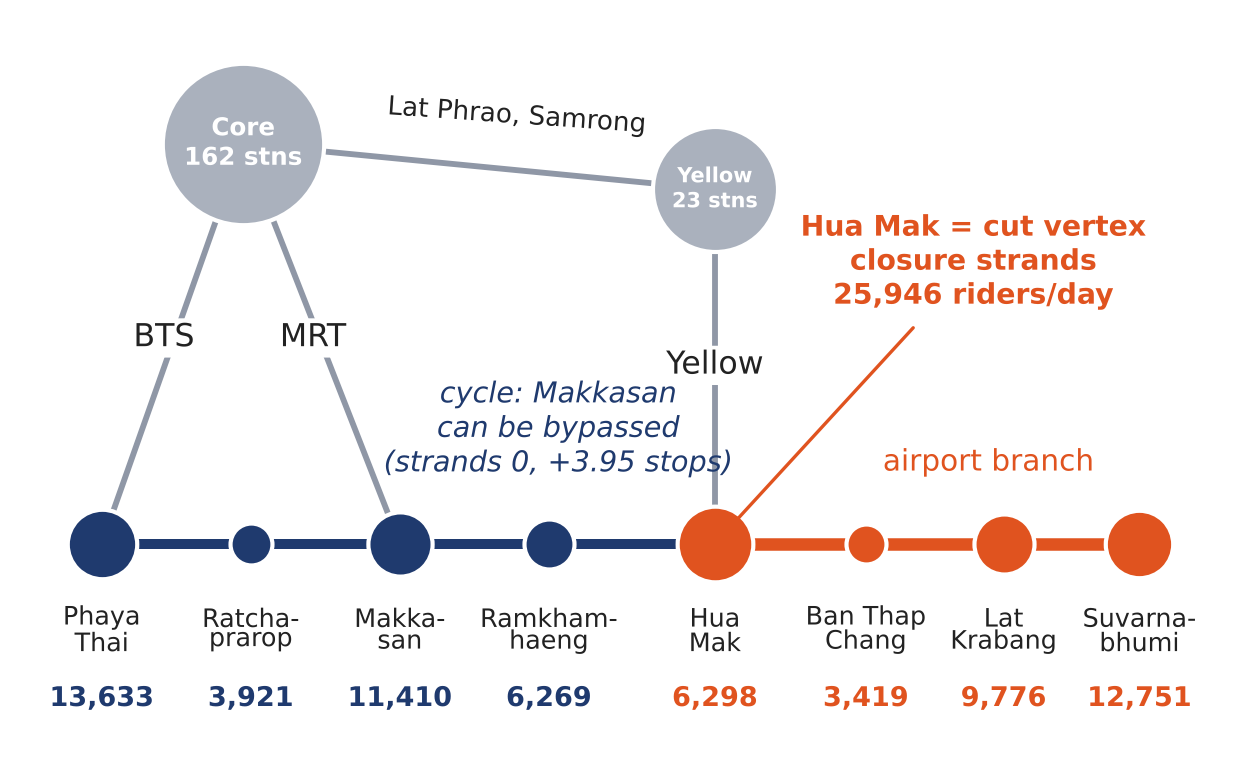

In [11]:
import matplotlib.pyplot as plt
plt.rcParams['font.family']='DejaVu Sans'
NAVY='#1f3a6e'; ORG='#e0531f'; GREY='#8f97a6'; LG='#c9ccd3'; INK='#222'
FW,FH=10.0/2.54,6.0/2.54
fig,ax=plt.subplots(figsize=(FW,FH),dpi=300)
y0=1.0
X={'A8':0.0,'A7':0.79,'A6':1.58,'A5':2.37,'A4':3.25,'A3':4.05,'A2':4.78,'A1':5.5}
nm={'A8':('Phaya\nThai','13,633'),'A7':('Ratcha-\nprarop','3,921'),'A6':('Makka-\nsan','11,410'),'A5':('Ramkham-\nhaeng','6,269'),
    'A4':('Hua\nMak','6,298'),'A3':('Ban Thap\nChang','3,419'),'A2':('Lat\nKrabang','9,776'),'A1':('Suvarna-\nbhumi','12,751')}
P={k:(v,y0) for k,v in X.items()}; P['CORE']=(0.75,2.75); P['YL']=(3.25,2.55)
def E(a,b,c=LG,lw=2.2,ls='-',z=1):
    ax.plot([P[a][0],P[b][0]],[P[a][1],P[b][1]],color=c,lw=lw,ls=ls,zorder=z,solid_capstyle='round')
seq=['A8','A7','A6','A5','A4','A3','A2','A1']
for a,b in zip(seq,seq[1:]):
    E(a,b,ORG if a in('A4','A3','A2') else NAVY,3 if a in('A4','A3','A2') else 2.4,z=2)
E('A8','CORE',GREY,1.4); E('A6','CORE',GREY,1.4); E('A4','YL',GREY,1.4); E('YL','CORE',GREY,1.4)
lab=dict(fontsize=7.6,color=INK,ha='center',va='center',zorder=6,bbox=dict(boxstyle='round,pad=0.12',fc='white',ec='none'))
ax.text(0.33,1.9,'BTS',**lab); ax.text(1.12,1.9,'MRT',**lab); ax.text(3.25,1.78,'Yellow',**lab)
ax.text(2.2,2.8,'Lat Phrao, Samrong',fontsize=6.3,color=INK,ha='center',rotation=-4)
# grey aggregate nodes
ax.scatter(*P['CORE'],s=1500,color='#aab1bd',zorder=3,edgecolor='white',lw=1)
ax.text(P['CORE'][0],P['CORE'][1],'Core\n162 stns',fontsize=5.9,ha='center',va='center',color='white',fontweight='bold',zorder=4)
ax.scatter(*P['YL'],s=900,color='#aab1bd',zorder=3,edgecolor='white',lw=1)
ax.text(P['YL'][0],P['YL'][1],'Yellow\n23 stns',fontsize=5.0,ha='center',va='center',color='white',fontweight='bold',zorder=4)
RID=W.round().to_dict()
for k in seq:
    c=ORG if k in('A4','A3','A2','A1') else NAVY
    s=30+RID[k]/55
    ax.scatter(*P[k],s=s if k!='A4' else 330,color=c,zorder=5,edgecolor='white',lw=1)
    n,_=nm[k]; v=f'{RID[k]:,.0f}'; ax.text(P[k][0],y0-0.27,n,fontsize=6.1,ha='center',va='top',color=INK,linespacing=0.95)
    ax.text(P[k][0],y0-0.62,v,fontsize=6.5,ha='center',va='top',color=ORG if k in('A3','A2','A1','A4') else NAVY,fontweight='bold')
# callouts
ax.annotate(f"Hua Mak = cut vertex\nclosure strands\n{R.loc['Hua Mak','stranded']:,.0f} riders/day",xy=P['A4'],xytext=(4.62,2.05),fontsize=6.8,color=ORG,fontweight='bold',ha='center',
            arrowprops=dict(arrowstyle='-',color=ORG,lw=0.8),zorder=7)
ax.text(2.42,1.5,f"cycle: Makkasan\ncan be bypassed\n(strands 0, +{R.loc['Makkasan/Phetchaburi','extra_stops']:.2f} stops)",fontsize=6.9,color=NAVY,ha='center',va='center',style='italic')
ax.text(4.7,y0+0.32,'airport branch',fontsize=7.1,color=ORG,ha='center')
ax.set_xlim(-0.38,5.88); ax.set_ylim(0.15,3.25); ax.axis('off')
plt.subplots_adjust(0,0,1,1); plt.savefig('page_figure.png', dpi=300)
plt.show()


## 9. Check against the reported results

In [12]:
checks = {
    'ARL riders/day (weight window) = 67,476': round(W.sum()) == 67476,
    'network = 193 nodes, 203 edges, 17 transfers': (G.number_of_nodes(), G.number_of_edges(), n_transfer) == (193, 203, 17),
    'Hua Mak first, strands 25,946 (38.5%)': R.index[0] == 'Hua Mak' and round(R.loc['Hua Mak', 'stranded']) == 25946 and round(R.loc['Hua Mak', 'stranded_pct'], 1) == 38.5,
    'Phaya Thai and Makkasan strand 0': R.loc['Phaya Thai', 'stranded'] == 0 and R.loc['Makkasan/Phetchaburi', 'stranded'] == 0,
    'Makkasan detour = +3.95 stops': round(R.loc['Makkasan/Phetchaburi', 'extra_stops'], 2) == 3.95,
    'Wat Phra Sri Mahathat second, 7,743': R.index[1] == 'Wat Phra Sri Mahathat' and round(R['stranded'].iloc[1]) == 7743,
    'all-pairs: Wat Phra Sri Mahathat 1st (20.2%), Hua Mak 6th': AP.index[0] == 'Wat Phra Sri Mahathat' and round(AP['cut_pct'].iloc[0], 1) == 20.2 and AP.loc['Hua Mak', 'city_rank'] == 6,
    'all-pairs: Makkasan 16th, Phaya Thai 18th': AP.loc['Makkasan/Phetchaburi', 'city_rank'] == 16 and AP.loc['Phaya Thai', 'city_rank'] == 18,
    'robustness: Hua Mak first in 8 of 8 runs (37.6-38.5%)': (ROB['first'] == 'Hua Mak').all() and ROB['first_pct'].min() == 37.6 and ROB['first_pct'].max() == 38.5,
    'equal weights: Hua Mak 37.5%': EQ.index[0] == 'Hua Mak' and round(EQ.loc['Hua Mak', 'stranded_pct'], 1) == 37.5,
    '2022 network: Makkasan strands 24,348': R2022.index[0] == 'Makkasan/Phetchaburi' and round(R2022['stranded'].iloc[0]) == 24348,
    'structure: 11 cycles, 58 cut vertices, Hua Mak yes, Makkasan no': (STRUCT['cycles'], STRUCT['cut_vertices'], STRUCT['hua_mak_is_cut_vertex'], STRUCT['makkasan_is_cut_vertex']) == (11, 58, True, False),
}
for k, ok in checks.items():
    print('OK  ' if ok else 'FAIL', k)
print('\nAll reported results reproduced.' if all(checks.values()) else '\nSome results differ from the report: check the inputs and the configuration.')

OK   ARL riders/day (weight window) = 67,476
OK   network = 193 nodes, 203 edges, 17 transfers
OK   Hua Mak first, strands 25,946 (38.5%)
OK   Phaya Thai and Makkasan strand 0
OK   Makkasan detour = +3.95 stops
OK   Wat Phra Sri Mahathat second, 7,743
OK   all-pairs: Wat Phra Sri Mahathat 1st (20.2%), Hua Mak 6th
OK   all-pairs: Makkasan 16th, Phaya Thai 18th
OK   robustness: Hua Mak first in 8 of 8 runs (37.6-38.5%)
OK   equal weights: Hua Mak 37.5%
OK   2022 network: Makkasan strands 24,348
OK   structure: 11 cycles, 58 cut vertices, Hua Mak yes, Makkasan no

All reported results reproduced.
